# 05 · ElasticNet (strategies 4, 5 and 6)

This notebook runs the three strategies that do not use deep learning. They set the bar that the network has to reach.

**ElasticNet** is a logistic regression with two brakes. The first one (L1) switches off the genes that do not help. The second one (L2) spreads the weight among similar genes. The **mix** (`l1_ratio`) says how much each brake weighs. The **strength** (`C`) says how much they brake in total: a small C brakes a lot.

| Strategy | What it learns from |
|---|---|
| **4. Apply directly** | Only the source (TCGA + METABRIC). It is used as it is |
| **5. Local** | Only the n local patients |
| **6. Source + local** | The source and the n local patients together. The local patients add up to 50% of the weight |

**Convergence:** every model uses up to 1,000 iterations and a fixed seed (`random_state=0`). A first run with 300 iterations did not converge for the source model and for local ElasticNet. That changed the mean AUC by 0.004 or less, but the notebook was run again so that every model converges and the results can be reproduced.

**Input:** `data/processed/` and `data/experiment/examenes.csv` and `repeticiones.csv` (notebook 04).
**Output** (in `data/experiment/`): `elasticnet_fuente.joblib` (source model), `prob_elasticnet.parquet` (probability of each exam patient) and `auc_elasticnet.csv`. Tables and figures in `results/`.

**Time:** about 6 hours on a 10-core Mac, almost all of it in strategy 6. The notebook saves its progress after each exam and continues from there if it stops.

*Note: this notebook was run before the repository was translated. The code comments, printed text and figure labels in the saved outputs are in Spanish. The results are the same.*

In [1]:
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import cargar, fuente, zscore

warnings.filterwarnings("ignore", category=ConvergenceWarning)
EXP = ROOT / "data" / "experiment"
PARTS = EXP / "partes_05"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
PARTS.mkdir(exist_ok=True)

TARGETS = ["CPTAC", "SMC 2018"]
COLORS = {"CPTAC": "#534AB7", "SMC 2018": "#1D9E75"}
SHARE_MAIN, SHARES_SENS, N_SENS = 0.5, [0.25, 0.10], [10, 40]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def enet(C, l1_ratio):
    return LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=l1_ratio, C=C, max_iter=1000, tol=1e-3, random_state=0)

## Step 1 · Load and normalize the source

TCGA and METABRIC are normalized with their own mean and SD (z-score per gene). The 14 missing values of METABRIC are filled first with the median of the gene.

In [2]:
X_src, y_src, cohort_src = fuente()
N_SRC = len(y_src)
assert np.allclose(X_src.loc[cohort_src == "TCGA-BRCA"].mean(), 0, atol=1e-3)  # z-score bien hecho
pd.DataFrame({"pacientes": cohort_src.value_counts(), "% mutados": (100 * y_src.groupby(cohort_src).mean()).round(1)})

,pacientes,% mutados
METABRIC,1899,34.7
TCGA-BRCA,961,34.4


## Step 2 · Strategy 4: choose the mix and the strength with the source

5-fold cross-validation, **only with the source**. Each fold keeps the same proportion of TCGA, METABRIC and mutated tumors. Three mixes × three strengths are tested, and the combination with the highest validation AUC is chosen. Then the model is trained with the 2,860 patients.

CPTAC and SMC are not used to choose. This way the result is not inflated.

If `elasticnet_fuente.joblib` already exists, it is loaded and this step is skipped.

In [3]:
MODEL_FILE = EXP / "elasticnet_fuente.joblib"
GRID = [(l1, C) for l1 in (0.1, 0.5, 0.9) for C in (0.01, 0.05, 0.1)]

if MODEL_FILE.exists():
    src_model = joblib.load(MODEL_FILE)
    cv = pd.read_csv(TAB / "05_hiperparametros_fuente.csv")
else:
    strata = cohort_src + "_" + y_src.astype(str)
    folds = list(StratifiedKFold(5, shuffle=True, random_state=2026).split(X_src, strata))
    Xs, ys = X_src.to_numpy(), y_src.to_numpy()

    def cv_auc(l1, C, tr, te, Xs, ys):
        m = enet(C, l1).fit(Xs[tr], ys[tr])
        return l1, C, roc_auc_score(ys[te], m.decision_function(Xs[te]))

    cv = Parallel(n_jobs=-1)(delayed(cv_auc)(l1, C, tr, te, Xs, ys) for l1, C in GRID for tr, te in folds)
    cv = pd.DataFrame(cv, columns=["l1_ratio", "C", "auc"]).groupby(["l1_ratio", "C"]).auc.agg(["mean", "std"]).reset_index()
    cv.to_csv(TAB / "05_hiperparametros_fuente.csv", index=False)
    best = cv.loc[cv["mean"].idxmax()]
    src_model = enet(best.C, best.l1_ratio).fit(Xs, ys)
    joblib.dump(src_model, MODEL_FILE)

L1, C_SRC = src_model.l1_ratio, src_model.C
print(f"Elegido: mezcla l1_ratio = {L1}, fuerza C = {C_SRC}")
print("Genes con peso distinto de 0:", int((src_model.coef_ != 0).sum()), "de", X_src.shape[1])

Elegido: mezcla l1_ratio = 0.9, fuerza C = 0.05
Genes con peso distinto de 0: 1022 de 18040


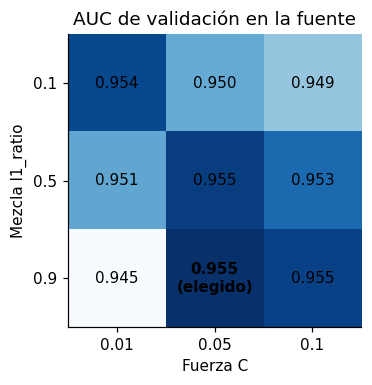

In [4]:
heat = cv.pivot(index="l1_ratio", columns="C", values="mean")
fig, ax = plt.subplots(figsize=(4.6, 3.6))
im = ax.imshow(heat, cmap="Blues")
for i, l1 in enumerate(heat.index):
    for j, C in enumerate(heat.columns):
        chosen = l1 == L1 and C == C_SRC
        ax.text(j, i, f"{heat.loc[l1, C]:.3f}" + ("\n(elegido)" if chosen else ""), ha="center", va="center",
                fontweight="bold" if chosen else "normal")
ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("Fuerza C")
ax.set_ylabel("Mezcla l1_ratio")
ax.set_title("AUC de validación en la fuente")
plt.tight_layout()
fig.savefig(FIG / "05_rejilla_fuente.png", bbox_inches="tight")

**How to read it:** each cell is the mean AUC of the 5 validation folds. If the values are similar, the choice does not matter much.

## Step 3 · Run the strategies in each exam

For each target cohort and each exam:
1. **Normalize the cohort** with the mean and SD of the patients that are **not** in the exam, without their labels. The rule is the same for the three strategies and every n.
2. **Strategy 4:** the source model, as it is, on the 40 exam patients.
3. **Strategy 5:** for each n and repetition, ElasticNet with only the n local patients. The mix is the one of the source. The strength is chosen with 3-fold cross-validation **inside the n local patients** (C = 0.01, 0.1, 1 or 10; on a tie, the smallest C). With 10 patients this validation is noisy, but it does not touch the exam.
4. **Strategy 6:** for each n and repetition, the source and the n local patients together, with the mix and strength of the source. Each local patient weighs `N_source / n`, so that together they add up to 50% of the weight. Then all weights are rescaled to add up to `N_source + n`, so that C means the same as in strategy 4. It starts from the source model, which gives the same result faster.
   - **Sensitivity:** local weights of 25% and 10%, only with n = 10 and 40.

The probability of being mutated is saved for each exam patient. The AUC is computed afterwards from those probabilities.

In [5]:
Xs, ys = X_src.to_numpy(), y_src.to_numpy()
exams = pd.read_csv(EXP / "examenes.csv")
reps = pd.read_csv(EXP / "repeticiones.csv")


def local_probs(x_loc, y_loc, x_exam):
    m = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=StratifiedKFold(3, shuffle=True, random_state=0),
                             penalty="elasticnet", solver="saga", l1_ratios=[L1], scoring="roc_auc",
                             max_iter=1000, tol=1e-3, random_state=0).fit(x_loc, y_loc)
    return m.predict_proba(x_exam)[:, 1]


def pooled_probs(x_loc, y_loc, x_exam, share, Xs, ys):
    n = len(y_loc)
    w = np.r_[np.ones(N_SRC), np.full(n, share * N_SRC / ((1 - share) * n))]
    w *= (N_SRC + n) / w.sum()
    m = enet(C_SRC, L1).set_params(warm_start=True)
    m.coef_, m.intercept_ = src_model.coef_.copy(), src_model.intercept_.copy()
    m.fit(np.vstack([Xs, x_loc]), np.r_[ys, y_loc], sample_weight=w)
    return m.predict_proba(x_exam)[:, 1]


# Xs e ys van como argumento: así joblib comparte la matriz de la fuente en lugar de copiarla en cada modelo.
def run(strategy, share, x_loc, y_loc, x_exam, Xs, ys):
    return local_probs(x_loc, y_loc, x_exam) if strategy == 5 else pooled_probs(x_loc, y_loc, x_exam, share, Xs, ys)


for name in TARGETS:
    x, y = cargar(name)
    for e in range(1, 6):
        part = PARTS / f"{name.replace(' ', '_')}_examen{e}.parquet"
        if part.exists():
            continue
        start = time.time()
        exam_ids = exams.query("cohorte == @name and examen == @e").muestra
        z = zscore(x, x.index.difference(exam_ids))
        x_exam, y_exam = z.loc[exam_ids].to_numpy(), y.loc[exam_ids]
        groups = reps.query("cohorte == @name and examen == @e").groupby(["n", "repeticion"]).muestra.apply(list)

        jobs = [(5, np.nan, n, r) for n, r in groups.index]
        jobs += [(6, SHARE_MAIN, n, r) for n, r in groups.index]
        jobs += [(6, s, n, r) for s in SHARES_SENS for n, r in groups.index if n in N_SENS]
        probs = Parallel(n_jobs=-1)(
            delayed(run)(s, w, z.loc[groups[n, r]].to_numpy(), y.loc[groups[n, r]].to_numpy(), x_exam, Xs, ys)
            for s, w, n, r in jobs)

        jobs.append((4, np.nan, 0, 0))
        probs.append(src_model.predict_proba(x_exam)[:, 1])
        out = pd.DataFrame([{"cohorte": name, "examen": e, "estrategia": s, "peso_locales": w, "n": n,
                             "repeticion": r, "muestra": m, "y": t, "prob": p}
                            for (s, w, n, r), ps in zip(jobs, probs) for m, t, p in zip(exam_ids, y_exam, ps)])
        out.to_parquet(part)
        print(f"{name} examen {e}: {len(jobs):,} modelos en {(time.time() - start) / 60:.0f} min")

CPTAC examen 1: 1,201 modelos en 28 min


CPTAC examen 2: 1,201 modelos en 28 min


CPTAC examen 3: 1,201 modelos en 28 min


CPTAC examen 4: 1,201 modelos en 32 min


CPTAC examen 5: 1,201 modelos en 27 min


SMC 2018 examen 1: 1,401 modelos en 38 min


SMC 2018 examen 2: 1,401 modelos en 40 min


SMC 2018 examen 3: 1,401 modelos en 40 min


SMC 2018 examen 4: 1,401 modelos en 40 min


SMC 2018 examen 5: 1,401 modelos en 40 min


## Step 4 · Join and compute the AUC

The files of each exam are joined. The AUC of each model is computed with the probability and the real label of the 40 exam patients.

In [6]:
prob = pd.concat([pd.read_parquet(p) for p in sorted(PARTS.glob("*.parquet"))], ignore_index=True)
keys = ["cohorte", "examen", "estrategia", "peso_locales", "n", "repeticion"]
auc = prob.groupby(keys, dropna=False).apply(lambda g: roc_auc_score(g.y, g.prob)).rename("auc").reset_index()
assert auc.groupby(["cohorte", "estrategia", "peso_locales", "n"], dropna=False).size().isin([5, 500]).all()

prob.drop(columns="y").to_parquet(EXP / "prob_elasticnet.parquet")
auc.to_csv(EXP / "auc_elasticnet.csv", index=False)
print(f"{len(auc):,} AUC guardados")

13,010 AUC guardados


## Step 5 · Summary

For each cohort, strategy and n: the **mean AUC** and the **SD across repetitions**. The SD is computed inside each exam (100 repetitions) and then averaged over the 5 exams. Strategy 4 has only one value per exam, so it has no SD.

In [7]:
per_exam = auc.groupby(keys[:-1], dropna=False).auc.agg(["mean", "std"])
summary = (per_exam.groupby(["cohorte", "estrategia", "peso_locales", "n"], dropna=False).mean()
           .rename(columns={"mean": "AUC promedio", "std": "DE entre repeticiones"}).round(3))
summary.to_csv(TAB / "05_resumen.csv")
summary[~summary.index.get_level_values("peso_locales").isin(SHARES_SENS)]

AUC promedio  DE entre repeticiones
cohorte  estrategia peso_locales n                                      
CPTAC    4          NaN          0          0.930                    NaN
         5          NaN          10         0.714                  0.157
                                 15         0.764                  0.141
                                 20         0.815                  0.111
                                 40         0.879                  0.041
         6          0.5          10         0.931                  0.010
                                 15         0.932                  0.011
                                 20         0.931                  0.012
                                 40         0.931                  0.010
SMC 2018 4          NaN          0          0.865                    NaN
         5          NaN          10         0.654                  0.116
                                 15         0.695                  0.108
                                 20         0.731                  0.081
                                 40         0.773                  0.048
                                 80         0.791                  0.026
         6          0.5          10         0.853                  0.015
                                 15         0.852                  0.015
                                 20         0.851                  0.016
                                 40         0.846                  0.016
                                 80         0.834                  0.014

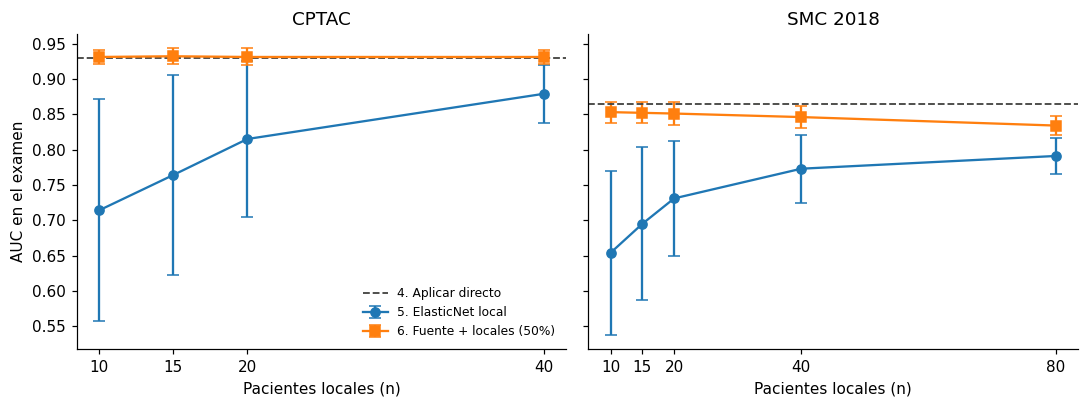

In [8]:
res = summary.reset_index()
main = res[res.peso_locales.isna() | (res.peso_locales == SHARE_MAIN)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, name in zip(axes, TARGETS):
    d = main[main.cohorte == name]
    for s, label, marker in [(5, "5. ElasticNet local", "o"), (6, "6. Fuente + locales (50%)", "s")]:
        t = d[d.estrategia == s]
        ax.errorbar(t.n, t["AUC promedio"], yerr=t["DE entre repeticiones"], marker=marker, capsize=4, label=label)
    ax.axhline(d[d.estrategia == 4]["AUC promedio"].iloc[0], color="#444441", ls="--", lw=1.2, label="4. Aplicar directo")
    ax.set_title(name)
    ax.set_xlabel("Pacientes locales (n)")
    ax.set_xticks(sorted(d[d.n > 0].n.unique()))
axes[0].set_ylabel("AUC en el examen")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
fig.savefig(FIG / "05_auc_vs_n.png", bbox_inches="tight")

**How to read it:** each point is the mean AUC with n local patients. The bars show how much it changes depending on which patients were drawn (± SD). The dashed line is "apply directly", the mean of the 5 exams. Where a curve is above the line, that strategy has a higher AUC than not adjusting anything.

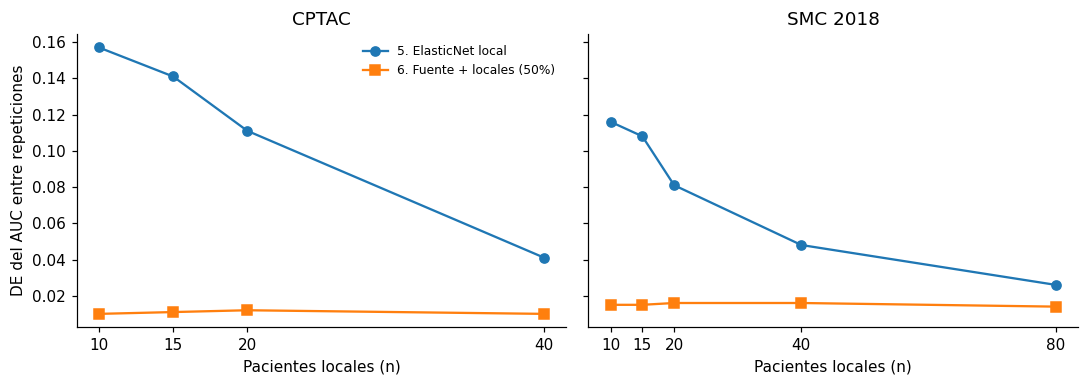

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, name in zip(axes, TARGETS):
    d = main[(main.cohorte == name) & (main.estrategia != 4)]
    for s, label, marker in [(5, "5. ElasticNet local", "o"), (6, "6. Fuente + locales (50%)", "s")]:
        t = d[d.estrategia == s]
        ax.plot(t.n, t["DE entre repeticiones"], marker=marker, label=label)
    ax.set_title(name)
    ax.set_xlabel("Pacientes locales (n)")
    ax.set_xticks(sorted(d.n.unique()))
axes[0].set_ylabel("DE del AUC entre repeticiones")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "05_de_vs_n.png", bbox_inches="tight")

**How to read it:** lower = more stable. In other words, the AUC depends less on which patients were drawn. The SD is expected to go down as n grows.

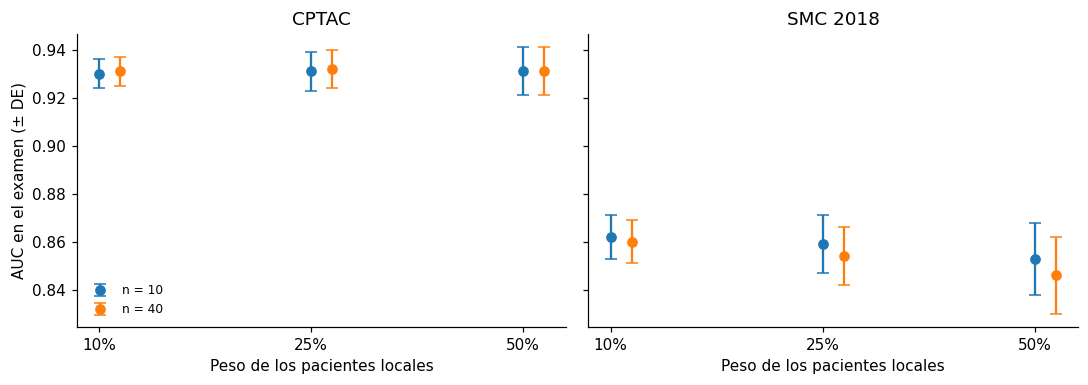

In [10]:
sens = res[(res.estrategia == 6) & res.n.isin(N_SENS)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, name in zip(axes, TARGETS):
    for k, n in enumerate(N_SENS):
        t = sens[(sens.cohorte == name) & (sens.n == n)].sort_values("peso_locales")
        ax.errorbar(np.arange(len(t)) + 0.1 * k, t["AUC promedio"], yerr=t["DE entre repeticiones"],
                    marker="o", capsize=4, ls="none", label=f"n = {n}")
    ax.set_xticks(range(3), ["10%", "25%", "50%"])
    ax.set_title(name)
    ax.set_xlabel("Peso de los pacientes locales")
axes[0].set_ylabel("AUC en el examen (± DE)")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "05_sensibilidad_peso.png", bbox_inches="tight")

**How to read it:** each point is strategy 6 with a different weight for the local patients. 50% is the main analysis. 10% and 25% are the sensitivity analysis, fixed in advance. If the three give almost the same result, the conclusion does not depend on the chosen weight.